# DeMa refinements and SSM baseline

AntMaze target: 538. HalfCheetah target: 12,000.

Three training runs and 100 tests per model per run.


In [ ]:
!pip install -q numpy==2.5.3 pandas==3.0.6 matplotlib==3.11.2 wandb==0.31.0

In [1]:
from pathlib import Path
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

records = json.loads(Path("data/experiment_records.json").read_text())
figures = Path("figures/variants")
figures.mkdir(parents=True, exist_ok=True)
seeds = [42, 43, 44]
colors = {"DT": "#147BE8", "DeMa": "#E52666", "CQL": "#15945B",
          "SSM": "#7753D6", "DeMa + SER": "#F09500"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12,
                     "text.color": "black", "axes.labelcolor": "black",
                     "xtick.color": "black", "ytick.color": "black",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "savefig.facecolor": "white"})

def load(prefix, seed):
    return records[f"{prefix}_seed{seed}.json"]

def evaluations(prefix, model, target):
    rows = []
    for seed in seeds:
        data = load(prefix, seed)
        row = data["evaluation"] if model == "CQL" else data["models"][model]["evaluations"][str(float(target))]
        scores = np.asarray(row["return_scores"])
        assert len(scores) == row["rollouts"] == 100
        assert np.isfinite(scores).all()
        assert np.isclose(scores.mean(), row["return_mean"])
        assert np.isclose(np.median(scores), row["return_median"])
        rows.append(row)
    return rows

def summary(label, rows, target, maze=False):
    rewards = [r["return_mean"] for r in rows]
    result = {"Model": label, "Target": target, "Average reward": np.mean(rewards)}
    if maze:
        result["Goal arrival (%)"] = sum(np.count_nonzero(np.asarray(r["return_scores"]) > 0) for r in rows) / 3
    return result

def table(rows):
    display(pd.DataFrame(rows).style.format(precision=1, thousands=","))

def save(fig, name):
    fig.savefig(figures / name, dpi=400)
    plt.show()
    plt.close(fig)

def losses(cases, name):
    fig, axes = plt.subplots((len(cases) + 1) // 2, 2, figsize=(11, 3.7 * ((len(cases) + 1) // 2)),
                             layout="constrained", squeeze=False)
    # Keep training and validation curves separate from control reward.
    for ax, (title, prefix, model) in zip(axes.flat, cases):
        histories = [load(prefix, seed)["models"][model]["loss_history"] for seed in seeds]
        for key, label, color, line in [("loss", "Training", "#147BE8", "-"),
                                         ("validation_loss", "Validation", "#D87700", "--")]:
            steps = sorted(set.intersection(*[{p["step"] for p in h if key in p} for h in histories]))
            values = np.mean([[next(p[key] for p in h if p["step"] == step) for step in steps] for h in histories], axis=0)
            choose = np.asarray(steps) >= 10000
            ax.plot(np.asarray(steps)[choose] / 1000, values[choose], color=color,
                    linestyle=line, linewidth=2.4, label=label)
        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Training updates (thousands)")
        ax.set_ylabel("Action prediction loss")
        ax.set_xlim(10, 100)
        ax.set_xticks([10, 50, 100])
        ax.set_ylim(bottom=0)
        ax.grid(axis="y", color="#DBE5EF", linewidth=0.7)
    for row in axes:
        visible = [ax for ax in row if ax.has_data()]
        top = max(ax.get_ylim()[1] for ax in visible)
        for ax in visible:
            ax.set_ylim(0, top * 1.10)
    for ax in list(axes.flat)[len(cases):]:
        ax.set_visible(False)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False, fontsize=11)
    save(fig, name)


## SER: goal reaching

Higher goal arrival is better.

,Model,Target,Average reward,Goal arrival (%)
0,DeMa,538,369.9,81.0
1,DeMa + SER,538,401.9,86.7


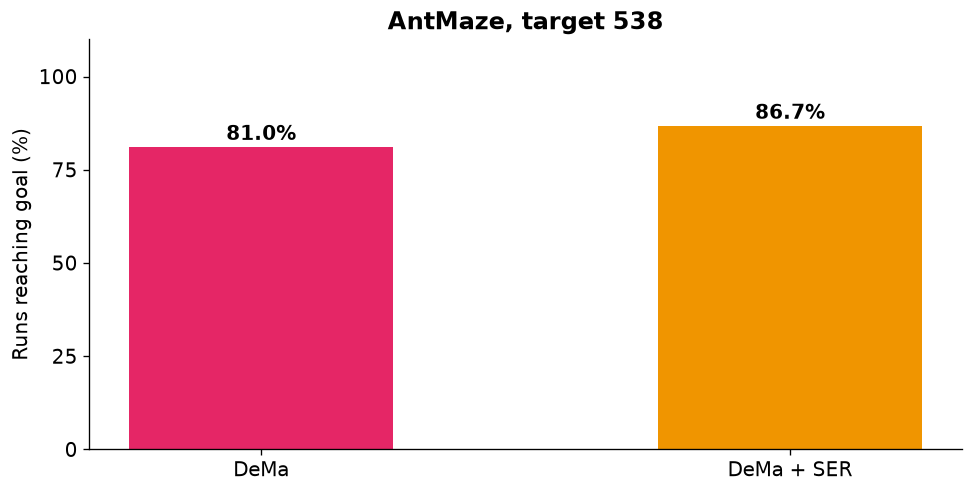

In [2]:
target = 538
ser = {
    "DeMa": evaluations("antmaze_dema", "DeMa", target),
    "DeMa + SER": evaluations("ser_dema", "DeMa", target)
}
table([summary(label, rows, target, True) for label, rows in ser.items()])
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
labels = list(ser)
rates = [summary(label, ser[label], target, True)["Goal arrival (%)"] for label in labels]
ax.bar(labels, rates, color=[colors[label] for label in labels], width=0.5)
ax.set_ylabel("Runs reaching goal (%)")
ax.set_ylim(0, 110)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_title("AntMaze, target 538", fontweight="bold")
for i, rate in enumerate(rates):
    ax.text(i, rate + 2, f"{rate:.1f}%", ha="center", fontweight="bold")
save(fig, "ser_goals.png")


## SER: rewards across training runs

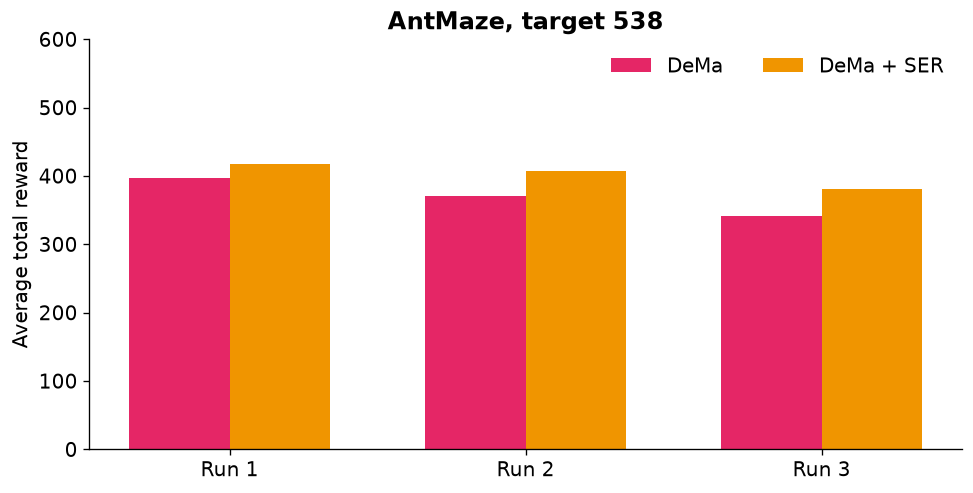

In [3]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
x = np.arange(3)
for i, label in enumerate(["DeMa", "DeMa + SER"]):
    ax.bar(x + (i - 0.5) * 0.34, [r["return_mean"] for r in ser[label]],
           width=0.34, color=colors[label], label=label)
ax.set_xticks(x, ["Run 1", "Run 2", "Run 3"])
ax.set_title("AntMaze, target 538", fontweight="bold")
ax.set_ylabel("Average total reward")
ax.set_ylim(0, 600)
ax.legend(frameon=False, ncol=2, loc="upper right")
save(fig, "ser_reward.png")


## SER learning curves

SER training uses blended targets. Validation uses recorded actions in both panels. Curves average three runs from 10,000 updates.

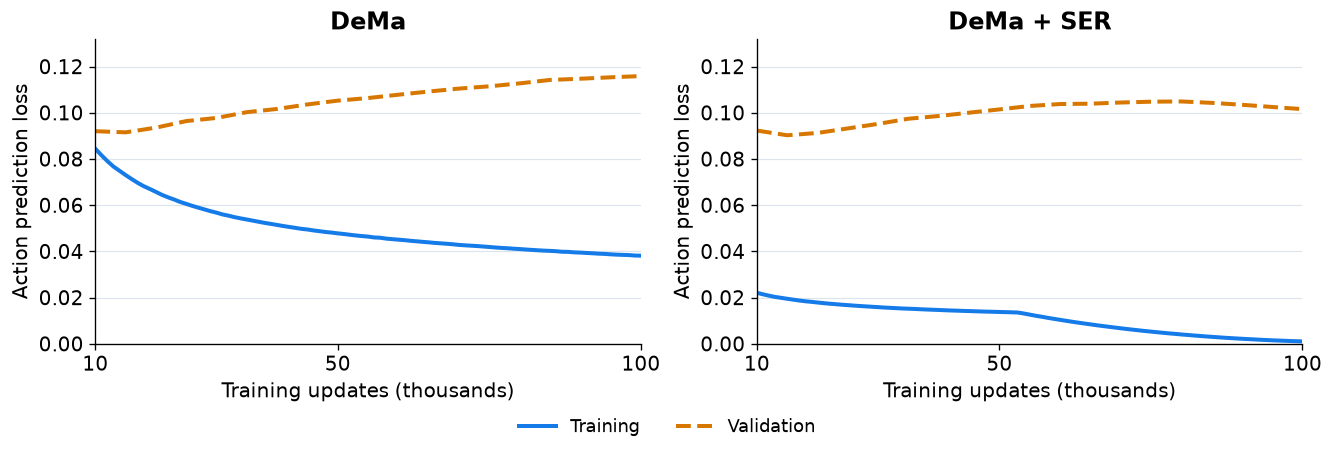

In [4]:
losses([("DeMa", "antmaze_dema", "DeMa"), ("DeMa + SER", "ser_dema", "DeMa")], "ser_loss.png")

## DeMa and Multi-Grained SSM

Both models use grouped inputs.


In [5]:
grouped = {}
for task, target, dema_prefix, ssm_prefix in [
    ("HalfCheetah", 12000, "axis2_dema", "mgssm_grouped_halfcheetah"),
    ("AntMaze", 538, "dema_grouped_antmaze", "mgssm_grouped_antmaze")
]:
    grouped[task, "DeMa", target] = evaluations(dema_prefix, "DeMa", target)
    grouped[task, "SSM", target] = evaluations(ssm_prefix, "Multi-Grained SSM", target)
table([dict(Task=task, **summary(model, rows, target, task == "AntMaze"))
       for (task, model, target), rows in grouped.items()])


,Task,Model,Target,Average reward,Goal arrival (%)
0,HalfCheetah,DeMa,"12,000","11,637.5",nan
1,HalfCheetah,SSM,"12,000","9,735.6",nan
2,AntMaze,DeMa,538,387.9,86.0
3,AntMaze,SSM,538,343.0,83.7


## Grouped-model learning curves

Average of three training runs, shown from 10,000 updates.

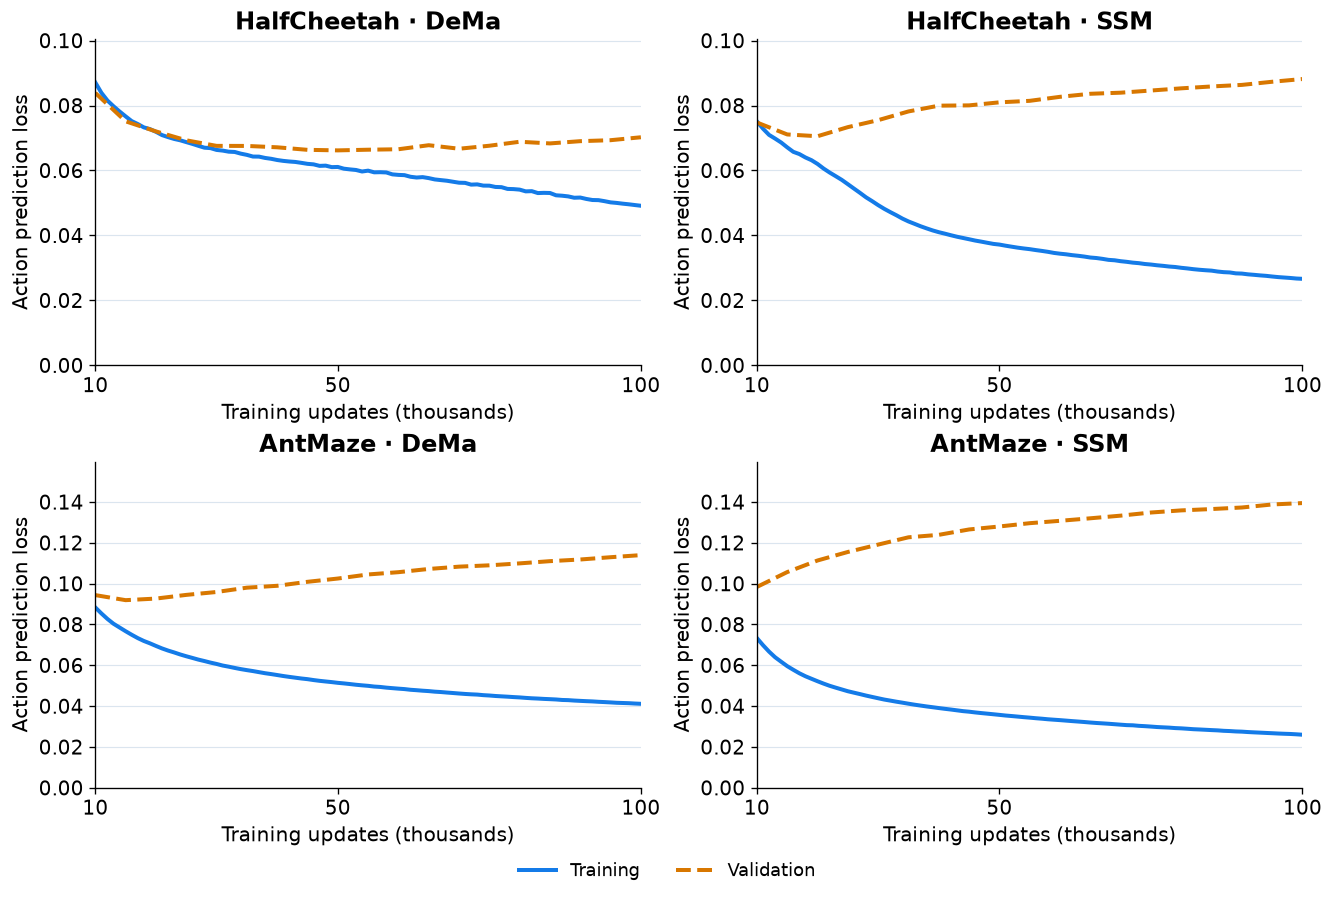

In [6]:
losses([("HalfCheetah · DeMa", "axis2_dema", "DeMa"),
        ("HalfCheetah · SSM", "mgssm_grouped_halfcheetah", "Multi-Grained SSM"),
        ("AntMaze · DeMa", "dema_grouped_antmaze", "DeMa"),
        ("AntMaze · SSM", "mgssm_grouped_antmaze", "Multi-Grained SSM")], "ssm_loss.png")

## W&B histories

In [7]:
names = [f"{prefix}_seed{seed}" for prefix in ["ser_dema", "antmaze_dema", "axis2_dema", "mgssm_grouped_halfcheetah", "dema_grouped_antmaze", "mgssm_grouped_antmaze"] for seed in seeds]
# Optional access to the recorded W&B histories.
logs = {}
if os.environ.get("WANDB_API_KEY"):
    import wandb
    api = wandb.Api(timeout=30)
    entity = os.environ.get("WANDB_ENTITY") or api.default_entity
    project = os.environ.get("WANDB_PROJECT", "dema-vs-dt")
    for run in api.runs(f"{entity}/{project}"):
        if run.name in names:
            logs[run.name] = list(run.scan_history(page_size=200))
    print(f"Loaded {len(logs)} run histories")